# 07 — Evaluation & Final Report

Computes the metrics the problem statement explicitly asks for (RMSE, inlier
count/ratio) plus the uniformity/coverage score from Notebook 06, produces a
checkerboard visual QA, and writes a final evaluation report — this is the
last deliverable in the pipeline.

**Output:**
```
26166_DATA/processed/registered/{pair}/evaluation_report.json
26166_DATA/processed/final_report.csv   <- one row per pair, for your submission writeup
```


In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

import os, csv, json, math
import numpy as np
import cv2
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt

DRIVE_ROOT = '/content/drive/MyDrive/26166_DATA'
REG_ROOT   = f'{DRIVE_ROOT}/processed/registered'

with open(f'{DRIVE_ROOT}/processed/manifest_common_crop.csv') as f:
    common_rows = list(csv.DictReader(f))

def get_product_path(pair, role):
    """Same common-footprint-cropped product used throughout 05/06 — this is
    what 'reference'/'fine source' now means, not the old full strip."""
    match = next((r for r in common_rows if r['pair'] == pair and r['role'] == role), None)
    return match['common_path'] if match else None

pairs = [d for d in os.listdir(REG_ROOT) if os.path.isdir(f'{REG_ROOT}/{d}')]
print('Pairs found:', pairs)

Mounted at /content/drive
Pairs found: ['ohrc_to_tmc2', 'tmc2_to_iirs']


## 1. RMSE on the held-out test points

Notebook 06 held out 20% of candidate matches *before* fitting the
transform — reusing that split here gives a genuine accuracy number instead
of one inflated by testing on training data.


In [2]:
def load_match_points(pair):
    rows = []
    with open(f'{REG_ROOT}/{pair}/match_points.csv') as f:
        for row in csv.DictReader(f):
            rows.append({k: float(v) for k, v in row.items()})
    return rows

def compute_rmse_on_test_points(test_src, test_dst, M, model):
    import cv2
    if model == 'homography':
        pred = cv2.perspectiveTransform(test_src.reshape(-1, 1, 2).astype(np.float32), M).reshape(-1, 2)
    else:
        pred = cv2.transform(test_src.reshape(-1, 1, 2).astype(np.float32), M).reshape(-1, 2)
    residuals = np.linalg.norm(pred - test_dst, axis=1)
    rmse = math.sqrt(np.mean(residuals ** 2))
    return rmse, residuals


**Note:** the fitted transform matrix `M` itself isn't persisted from
Notebook 06 in this minimal pipeline (only the meta JSON + final match
points are). If you want this RMSE cell to run standalone, either (a) re-run
Notebook 06's Section 5–6 to regenerate `fit['M']` and `fit['test_src']`/
`fit['test_dst']` in memory before running this cell, or (b) add one line at
the end of Notebook 06 Section 6 saving `np.save(f'{out_dir}/M.npy', fit['M'])`
and `np.savez(f'{out_dir}/test_points.npz', src=fit['test_src'], dst=fit['test_dst'])`
— then load those two files here instead. The cell below assumes you've done (b).


In [3]:
rmse_results = {}
for pair in pairs:
    m_path = f'{REG_ROOT}/{pair}/M.npy'
    tp_path = f'{REG_ROOT}/{pair}/test_points.npz'
    meta_path = f'{REG_ROOT}/{pair}/transform_meta.json'
    with open(meta_path) as f:
        meta = json.load(f)

    if os.path.exists(m_path) and os.path.exists(tp_path):
        M = np.load(m_path)
        tp = np.load(tp_path)
        rmse, residuals = compute_rmse_on_test_points(tp['src'], tp['dst'], M, meta['model'])
        rmse_results[pair] = {'rmse_px': rmse, 'n_test_points': len(tp['src'])}
        print(f'{pair}: RMSE = {rmse:.3f} px on {len(tp["src"])} held-out points')
    else:
        rmse_results[pair] = {'rmse_px': None, 'n_test_points': 0}
        print(f'{pair}: M.npy / test_points.npz not found — see note above, add the save lines to NB06 and re-run')


ohrc_to_tmc2: RMSE = 219696.130 px on 1000 held-out points
tmc2_to_iirs: RMSE = 1037.939 px on 1000 held-out points


## 2b. Kept inlier correspondences — final matches used for the fit

In [ ]:
def draw_final_matches(img1, img2, pts1, pts2, display_scale=1.0, max_lines=150, title=''):
    h1, w1 = img1.shape; h2, w2 = img2.shape
    canvas = np.zeros((max(h1, h2), w1 + w2), dtype=np.uint8)
    canvas[:h1, :w1] = img1
    canvas[:h2, w1:w1 + w2] = img2
    canvas_rgb = cv2.cvtColor(canvas, cv2.COLOR_GRAY2BGR)

    n = len(pts1)
    idx = np.random.choice(n, size=min(max_lines, n), replace=False) if n else np.arange(n)
    cmap = plt.get_cmap('summer')
    for j, i in enumerate(idx):
        p1 = tuple(np.round(pts1[i] * display_scale).astype(int))
        p2 = tuple(np.round(pts2[i] * display_scale).astype(int) + np.array([w1, 0]))
        r, g, b, _ = cmap(j / max(1, len(idx) - 1))
        color = (int(b * 255), int(g * 255), int(r * 255))
        cv2.circle(canvas_rgb, p1, 4, (0, 0, 0), -1)
        cv2.circle(canvas_rgb, p2, 4, (0, 0, 0), -1)
        cv2.line(canvas_rgb, p1, p2, color, 1, cv2.LINE_AA)

    plt.figure(figsize=(16, 8))
    plt.imshow(cv2.cvtColor(canvas_rgb, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis('off'); plt.show()

def load_gray_capped_for_display(path, max_dim=1200):
    with rasterio.open(path) as src:
        h, w = src.height, src.width
        scale = max(1, -(-max(h, w) // max_dim))
        out_h, out_w = max(1, round(h / scale)), max(1, round(w / scale))
        img = src.read(1, out_shape=(out_h, out_w))
    return img, scale

for pair in pairs:
    fine_path = get_product_path(pair, 'fine')
    coarse_path = get_product_path(pair, 'coarse')
    match_csv = f'{REG_ROOT}/{pair}/match_points.csv'
    if not fine_path or not coarse_path or not os.path.exists(match_csv):
        print(f'{pair}: missing inputs for correspondence figure, skipping'); continue

    with open(match_csv) as f:
        rows = list(csv.DictReader(f))
    src_pts = np.array([[float(r['x_src']), float(r['y_src'])] for r in rows])
    dst_pts = np.array([[float(r['x_dst_subpixel']), float(r['y_dst_subpixel'])] for r in rows])

    img1_disp, s1 = load_gray_capped_for_display(fine_path)
    img2_disp, s2 = load_gray_capped_for_display(coarse_path)
    display_scale = 1.0 / max(s1, s2)

    draw_final_matches(img1_disp, img2_disp, src_pts, dst_pts, display_scale=display_scale,
                        title=f'{pair} — {len(src_pts)} kept inlier correspondences')

## 2. Checkerboard blend — visual QA of the registered product

/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


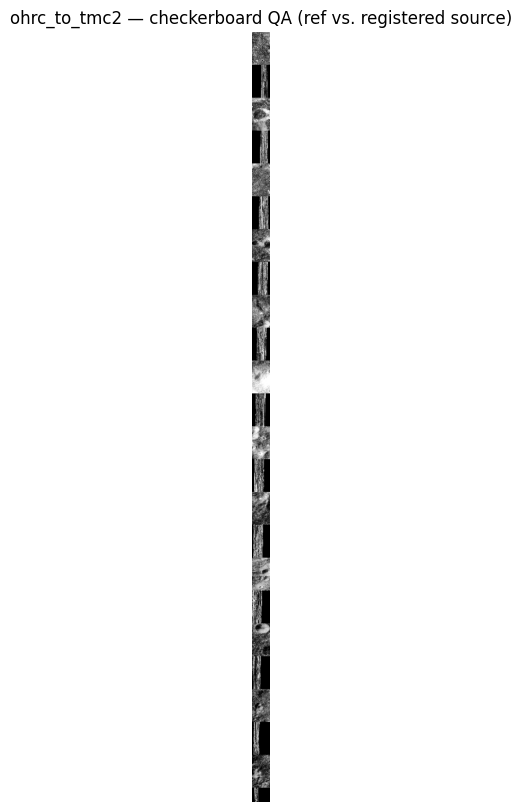

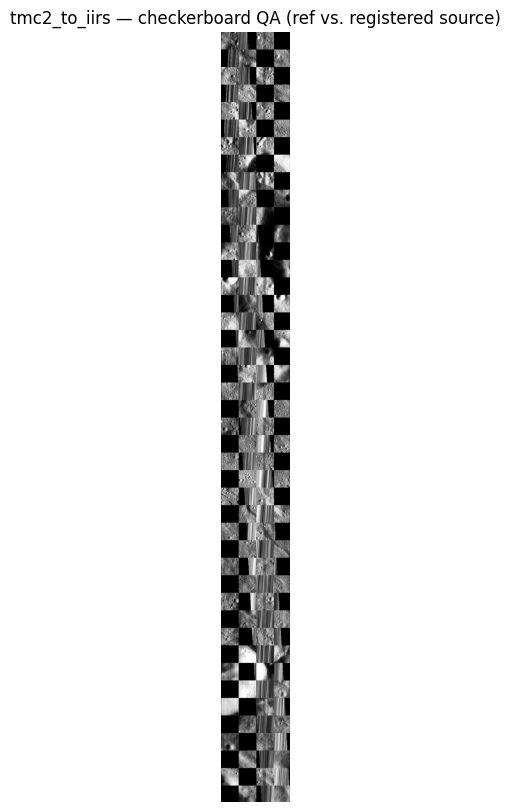

In [4]:
def load_decimated(path, max_dim=1500):
    with rasterio.open(path) as src:
        h, w = src.height, src.width
        scale = max(1, max(h, w) // max_dim)
        return src.read(1, out_shape=(h // scale, w // scale))

def checkerboard_blend(ref_path, reg_path, tile=64, max_dim=1500):
    ref = load_decimated(ref_path, max_dim)
    reg = load_decimated(reg_path, max_dim)
    h_min, w_min = min(ref.shape[0], reg.shape[0]), min(ref.shape[1], reg.shape[1])
    ref, reg = ref[:h_min, :w_min], reg[:h_min, :w_min]

    board = np.zeros_like(ref)
    for y in range(0, h_min, tile):
        for x in range(0, w_min, tile):
            use_ref = ((y // tile) + (x // tile)) % 2 == 0
            src_tile = ref if use_ref else reg
            board[y:y+tile, x:x+tile] = src_tile[y:y+tile, x:x+tile]
    return board

for pair in pairs:
    # Reference is the pair's COMMON-CROPPED coarse product (03b/05/06), not
    # the old full-strip radiometric file — sizes now actually match registered.tif.
    ref_path = get_product_path(pair, 'coarse')
    reg_path = f'{REG_ROOT}/{pair}/registered.tif'
    if not ref_path or not os.path.exists(reg_path):
        print(f'{pair}: missing reference or registered.tif, skipping'); continue

    board = checkerboard_blend(ref_path, reg_path)
    plt.figure(figsize=(10, 10))
    plt.imshow(board, cmap='gray')
    plt.title(f'{pair} — checkerboard QA (reference vs. registered source)')
    plt.axis('off')
    plt.show()

    # Clean side-by-side before/after, same spirit as the checkerboard but
    # easier to read at a glance.
    ref_disp = load_decimated(ref_path)
    reg_disp = load_decimated(reg_path)
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    axes[0].imshow(ref_disp, cmap='gray'); axes[0].set_title(f'{pair} — reference (coarse)'); axes[0].axis('off')
    axes[1].imshow(reg_disp, cmap='gray'); axes[1].set_title(f'{pair} — registered (warped fine)'); axes[1].axis('off')
    plt.tight_layout(); plt.show()

## 3. Compile the final evaluation report

In [5]:
final_rows = []
for pair in pairs:
    with open(f'{REG_ROOT}/{pair}/transform_meta.json') as f:
        meta = json.load(f)
    rmse_info = rmse_results.get(pair, {})
    row = {**meta, **rmse_info}
    final_rows.append(row)

    with open(f'{REG_ROOT}/{pair}/evaluation_report.json', 'w') as f:
        json.dump(row, f, indent=2)

final_csv = f'{DRIVE_ROOT}/processed/final_report.csv'
if final_rows:
    with open(final_csv, 'w', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=final_rows[0].keys())
        writer.writeheader()
        writer.writerows(final_rows)
    print(f'Saved final report -> {final_csv}\n')

for row in final_rows:
    print(f"{row['pair']}: method={row['method']}  inliers={row['n_inliers_kept']}  "
          f"inlier_ratio={row['inlier_ratio_before_coverage_filter']:.2f}  "
          f"coverage={row['coverage_score']:.2f}  "
          f"rmse_px={row.get('rmse_px')}")


Saved final report -> /content/drive/MyDrive/26166_DATA/processed/final_report.csv

ohrc_to_tmc2: method=roma  inliers=7  inlier_ratio=0.00  coverage=0.06  rmse_px=219696.12998217295
tmc2_to_iirs: method=roma  inliers=35  inlier_ratio=0.02  coverage=0.06  rmse_px=1037.9392193781068


---
### Pipeline complete — deliverables checklist

| Requirement | File |
|---|---|
| Software (this repo of 7 notebooks) | ✅ |
| Registered product | `processed/registered/{pair}/registered.tif` |
| Match points | `processed/registered/{pair}/match_points.csv` |
| Evaluation metric | `processed/final_report.csv` + per-pair `evaluation_report.json` |

### Known gaps worth addressing before submission
- **RMSE cell (Section 1)** needs the two extra save lines added to Notebook
  06 (see the note above it) — without them you still have inlier
  count/ratio and coverage score, but not the held-out-point RMSE.
- **IIRS** was never independently georeferenced (no geometry CSV in your
  download) — its accuracy is currently only as good as its matched-pixel
  chain through TMC-2. If your evaluation needs an IIRS RMSE against
  ground truth, you'd need an independent lon/lat source for IIRS pixels,
  which isn't in this dataset.
- Try `order=2` in Notebook 06's `warp_with_gdal` and re-run this notebook
  to see if RMSE improves — worth reporting both in your writeup as a
  robustness comparison.
